# Part 2 Extra: Physics with loops - drop and bounce a ball ⚽

**Course part 2 - Decisions and Loops** (uses Lectures 4-6: `if`, lists, `while`, `for`).

What you will build:
1. Drop a ball from the top of a **100 m building** and time the fall - with a `while` loop.
2. Check the loop against the physics formula. (Spoiler: they agree!)
3. Make the ball **bounce**, and count the bounces until it stops.
4. Drop the same ball on the **Moon** 🌙.

> 🐍 *Pip says: "Real physics engines in video games work exactly like this: tiny steps, again and again."*

*The plotting cells use matplotlib - plotting is Lecture 10, for now just run them.*

In [1]:
import matplotlib.pyplot as plt   # drawing tools (plotting is Lecture 10 - just run it)
plt.rcParams["font.size"] = 12    # bigger text on the plots
print("Ready to drop!")

Ready to drop!


## 1. The big idea: tiny time steps
A computer can't follow a ball "smoothly". Instead we chop time into tiny steps of `dt` seconds (here `dt = 0.01`, one hundredth of a second) and repeat two simple rules:

1. **Gravity changes the speed:** every second, a falling ball gets 9.81 m/s faster (about 35 km/h faster every second!).
   In one tiny step: `velocity = velocity - g * dt`
2. **Speed changes the height:** in one tiny step the ball moves `velocity * dt` meters.
   `height = height + velocity * dt`

We use **velocity** = speed with a direction: **positive = going up, negative = going down**. That's why gravity *subtracts*.
We ignore air resistance (a heavy ball, not a feather).

In [2]:
g = 9.81            # gravity on Earth: m/s faster every second
dt = 0.01           # one time step: a hundredth of a second
height = 100.0      # start on the roof of a 100 m building
velocity = 0.0      # m/s (up is +, down is -). We just let go.
time = 0.0
while height > 0:                       # until the ball reaches the ground
    velocity = velocity - g * dt        # 1. gravity speeds it up (downwards)
    height = height + velocity * dt     # 2. move a tiny bit
    time = time + dt
print(f"Loop:    the ball lands after {time:.2f} s")
print(f"Formula: t = sqrt(2h/g)       = {(2 * 100 / g) ** 0.5:.2f} s")
print(f"Landing speed: {-velocity:.1f} m/s = {-velocity * 3.6:.0f} km/h")

Loop:    the ball lands after 4.52 s
Formula: t = sqrt(2h/g)       = 4.52 s
Landing speed: 44.3 m/s = 160 km/h


The physics formula for a fall from height $h$ is $t = \sqrt{2h/g}$ (in Python, `** 0.5` is the square root).
Our loop never used that formula - it only knew the two simple rules - and still got the same answer! 🎉

Let's draw the whole fall. This time we keep a list of the time and height after every step.

In [3]:
height = 100.0
velocity = 0.0
time = 0.0
times = [0.0]
heights = [100.0]
while height > 0:
    velocity = velocity - g * dt
    height = height + velocity * dt
    time = time + dt
    times.append(time)                  # remember this moment...
    heights.append(height)              # ...and where the ball was
print(f"{len(times)} moments recorded, last height: {heights[-1]:.2f} m")

453 moments recorded, last height: -0.43 m


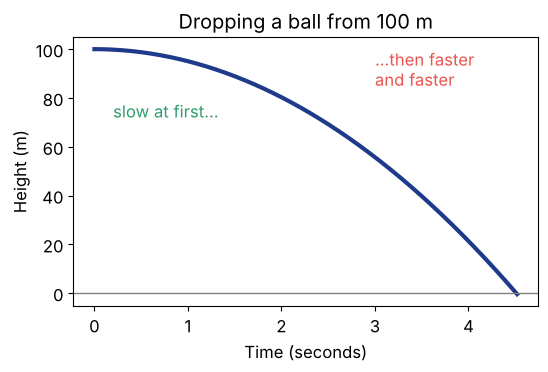

In [4]:
plt.figure(figsize=(6, 3.5))
plt.plot(times, heights, color="#1E3A8A", linewidth=3)
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("Time (seconds)")
plt.ylabel("Height (m)")
plt.title("Dropping a ball from 100 m")
plt.text(0.2, 72, "slow at first...", color="#2E9E6B")
plt.text(3.0, 85, "...then faster\nand faster", color="#E8554E")
plt.show()

### How small should the step be?
Let's try different step sizes with a `for` loop around our `while` loop (a loop inside a loop).

In [5]:
for dt in [1.0, 0.1, 0.01, 0.001]:
    height = 100.0
    velocity = 0.0
    time = 0.0
    while height > 0:
        velocity = velocity - g * dt
        height = height + velocity * dt
        time = time + dt
    print(f"dt = {dt:<6} -> lands after {time:.3f} s")
print(f"Formula      -> {(2 * 100 / g) ** 0.5:.3f} s")

dt = 1.0    -> lands after 5.000 s
dt = 0.1    -> lands after 4.500 s
dt = 0.01   -> lands after 4.520 s
dt = 0.001  -> lands after 4.515 s
Formula      -> 4.515 s


Big steps are rough (the computer only "looks" at the ball once per second). Smaller steps give answers closer to the formula, but take more rounds of the loop.
Here are big steps (`dt = 0.5`) next to tiny steps:

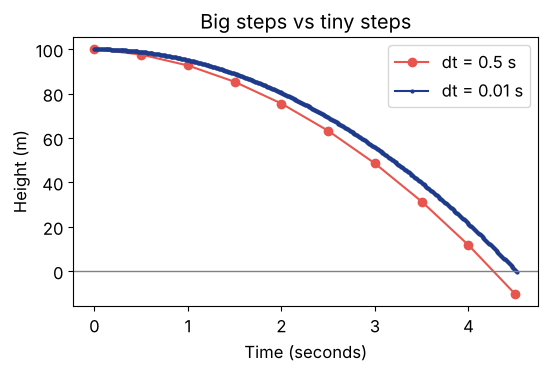

In [6]:
step_sizes = [0.5, 0.01]
colors = ["#E8554E", "#1E3A8A"]
plt.figure(figsize=(6, 3.5))
for k in range(2):
    dt = step_sizes[k]
    height = 100.0
    velocity = 0.0
    time = 0.0
    times = [0.0]
    heights = [100.0]
    while height > 0:
        velocity = velocity - g * dt
        height = height + velocity * dt
        time = time + dt
        times.append(time)
        heights.append(height)
    plt.plot(times, heights, "o-", color=colors[k], markersize=6 - 4 * k, label=f"dt = {dt} s")
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("Time (seconds)")
plt.ylabel("Height (m)")
plt.title("Big steps vs tiny steps")
plt.legend()
plt.show()

> **Try this:** change the height to 30 m (about a 10-floor building). How long is the fall? Does the formula agree?

## 2. Bounce! 🏀
New rule with an `if`: **when the ball hits the floor** (`height <= 0`):
- put it back on the floor (`height = 0`),
- **flip** its direction (down becomes up),
- and keep only **80%** of its speed (the rest becomes sound and heat).

The ball stops when it bounces up slower than 0.1 m/s - that's a jump of less than half a millimeter.
We drop it from 10 m (a third-floor balcony) and use a smaller step, `dt = 0.001`, because the last bounces are very short.

In [7]:
dt = 0.001
keep = 0.8                      # keep 80% of the speed at every bounce
height = 10.0
velocity = 0.0
time = 0.0
bounces = 0
bounce_speeds = []              # how fast the ball leaves the floor each time
times = [0.0]
heights = [10.0]
still_bouncing = True
print("Ready: ball at 10 m, at rest")

Ready: ball at 10 m, at rest


Now the loop: the same two rules as before, plus the new `if` for the floor.

In [8]:
while still_bouncing:
    velocity = velocity - g * dt
    height = height + velocity * dt
    time = time + dt
    if height <= 0:                       # hit the floor!
        height = 0.0
        velocity = -velocity * keep       # flip direction, keep 80%
        bounces = bounces + 1
        bounce_speeds.append(velocity)
        if velocity < 0.1:                # too slow to jump: it stopped
            still_bouncing = False
    times.append(time)
    heights.append(height)
print(f"The ball bounced {bounces} times and stopped after {time:.1f} s")

The ball bounced 22 times and stopped after 12.7 s


How high does each bounce go? A ball leaving the floor at speed $v$ rises to $v^2 / (2g)$ meters. Let's print the first 5 bounces:

In [9]:
for k in range(5):
    speed = bounce_speeds[k]
    top = speed ** 2 / (2 * g)          # how high this bounce goes
    print(f"Bounce {k + 1}: leaves the floor at {speed:5.2f} m/s, rises to {top:.2f} m")

Bounce 1: leaves the floor at 11.21 m/s, rises to 6.40 m
Bounce 2: leaves the floor at  8.96 m/s, rises to 4.09 m
Bounce 3: leaves the floor at  7.16 m/s, rises to 2.62 m
Bounce 4: leaves the floor at  5.73 m/s, rises to 1.67 m
Bounce 5: leaves the floor at  4.58 m/s, rises to 1.07 m


Every bounce reaches about **64%** of the one before, because 0.8 x 0.8 = 0.64 (the height depends on the speed *squared*).

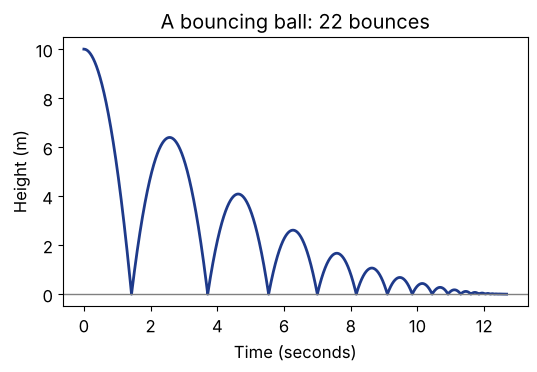

In [10]:
plt.figure(figsize=(6, 3.5))
plt.plot(times, heights, color="#1E3A8A", linewidth=2)
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("Time (seconds)")
plt.ylabel("Height (m)")
plt.title(f"A bouncing ball: {bounces} bounces")
plt.show()

> **Try this:**
> - A super-ball keeps 90%: set `keep = 0.9`. More bounces or fewer?
> - A tennis ball on clay keeps maybe 60%. Try `keep = 0.6`.

## 3. The same drop on the Moon 🌙
On the Moon gravity is much weaker: **1.62** m/s per second instead of 9.81.
(In 1971 the Apollo 15 astronaut David Scott dropped a hammer and a feather on the Moon - with no air, they landed together.)

Same loop, now inside a `for` loop over two worlds. We let the ball bounce for 20 seconds on each.

In [11]:
worlds = ["Earth", "Moon"]
gravities = [9.81, 1.62]
colors = ["#1E3A8A", "#F6B800"]
dt = 0.001
world_times = []                       # one list of times per world
world_heights = []                     # one list of heights per world
for k in range(2):
    g = gravities[k]
    height = 10.0
    velocity = 0.0
    time = 0.0
    times = []
    heights = []
    landed_at = 0.0                    # time of the first landing
    while time < 20:
        velocity = velocity - g * dt
        height = height + velocity * dt
        time = time + dt
        if height <= 0:
            if landed_at == 0.0:
                landed_at = time       # first touch of the ground
            height = 0.0
            velocity = -velocity * 0.8
        times.append(time)
        heights.append(height)
    world_times.append(times)
    world_heights.append(heights)
    print(f"{worlds[k]:5}: first landing after {landed_at:.2f} s (formula: {(2 * 10 / g) ** 0.5:.2f} s)")

Earth: first landing after 1.43 s (formula: 1.43 s)
Moon : first landing after 3.51 s (formula: 3.51 s)


That cell is longer than usual, but look closely: it's the bounce loop from before, just run twice (once per world).

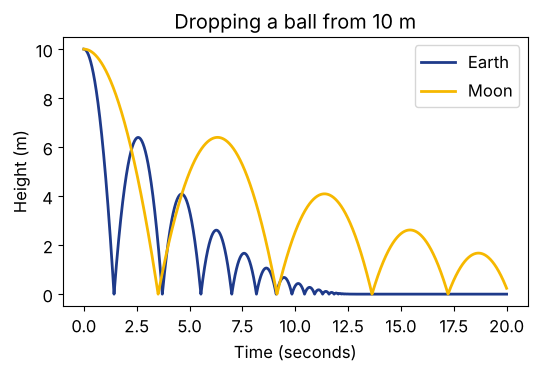

In [12]:
plt.figure(figsize=(6, 3.5))
for k in range(2):
    plt.plot(world_times[k], world_heights[k], color=colors[k], linewidth=2, label=worlds[k])
plt.xlabel("Time (seconds)")
plt.ylabel("Height (m)")
plt.title("Dropping a ball from 10 m")
plt.legend(loc="upper right")
plt.show()

On the Moon everything happens in **slow motion**: the first fall takes about 2.5 times longer, and the bounces are long and lazy.

### Watch them side by side (animation)
*This cell uses a small function (Lecture 7) and animation tools - just run it and press play.*

In [13]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(3.6, 3.2), dpi=72)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 10.8)
ax.set_xticks([0, 1], ["Earth", "Moon"])
ax.set_ylabel("Height (m)")
ax.axhline(0, color="gray")
balls = ax.scatter([0, 1], [10, 10], s=200, color=colors)

def update(frame):
    step = frame * 200                        # 200 steps of 0.001 s = 0.2 s per frame
    ax.set_title(f"t = {step * dt:.1f} s")
    balls.set_offsets([[0, world_heights[0][step]], [1, world_heights[1][step]]])

anim = FuncAnimation(fig, update, frames=75, interval=100)   # 75 frames = 15 seconds
plt.close()                                   # don't print an extra still picture
HTML(anim.to_jshtml())

# Challenges 🏆

**Easy** - Drop the ball on **Mars** (gravity 3.71). How long does a 100 m fall take? Put Mars into the Earth-Moon plot.

**Medium** - Find the smallest `keep` that gives **at least 20 bounces** from 10 m. (Hint: a `for` loop over `[0.5, 0.6, 0.7, 0.8, 0.9]` around the bounce loop.)

**Spicy** - Add **air resistance**: in every step also slow the ball down a little, `velocity = velocity - 0.1 * velocity * dt`. Drop it from a very high place (2,000 m). Does the speed keep growing, or does it reach a top speed? (Skydivers call this *terminal velocity*.)

> 🐍 *Pip says: "Two rules and a loop - and you just built a physics engine!"*